# Airway RNA-seq: the analysis without the agent

This notebook runs the same pipeline functions the agent calls (`pipeline/`), step by step, so a computational biologist can check the science directly. No language model is involved.

**Experiment.** Human airway smooth muscle cells from 4 donors, each untreated or treated with dexamethasone (a glucocorticoid). GEO [GSE52778](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE52778), Himes et al. 2014. We use NCBI's reprocessed raw counts (GRCh38.p13) and keep the 8 untreated/dex samples (GEO also has albuterol arms).

**Sections:** 1 data · 2 QC · 3 differential expression · 4 why the paired design matters · 5 pathway enrichment · 6 checks against the literature genes and against the authors' own analysis · 7 edge cases the agent must handle

In [1]:
import sys, warnings, logging
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")
logging.disable(logging.WARNING)  # gseapy logs tie warnings; ties are broken deterministically

import pandas as pd, numpy as np
from IPython.display import Image, display
from pipeline import config, data, qc, de, enrichment
pd.set_option("display.width", 140, "display.max_columns", 12)
OUT = config.RESULTS / "notebook"
print("pydeseq2", __import__("pydeseq2").__version__, "| gseapy", __import__("gseapy").__version__)

pydeseq2 0.5.4 | gseapy 1.3.1


## 1. Data

Raw files are checksummed on every load against `data/SOURCES.md`. The count matrix holds **raw integer read counts**: DESeq2 models counts directly, so we never feed it normalized values (FPKM/TPM).

In [2]:
ds = data.load_dataset()
print(ds.counts.shape, "genes x samples")
ds.metadata

(39376, 8) genes x samples


,title,cell,dex,ercc_mix
sample,,,,
GSM1275862,N61311_untreated,N61311,untrt,-
GSM1275863,N61311_Dex,N61311,trt,-
GSM1275866,N052611_untreated,N052611,untrt,-
GSM1275867,N052611_Dex,N052611,trt,1
GSM1275870,N080611_untreated,N080611,untrt,-
GSM1275871,N080611_Dex,N080611,trt,-
GSM1275874,N061011_untreated,N061011,untrt,1
GSM1275875,N061011_Dex,N061011,trt,1


In [3]:
lib = ds.counts.sum()
pd.DataFrame({"reads (M)": (lib / 1e6).round(1), "cell": ds.metadata.cell, "dex": ds.metadata.dex})

,reads (M),cell,dex
GSM1275862,21.0,N61311,untrt
GSM1275863,19.2,N61311,trt
GSM1275866,26.1,N052611,untrt
GSM1275867,39.1,N052611,trt
GSM1275870,27.5,N080611,untrt
GSM1275871,31.8,N080611,trt
GSM1275874,31.3,N061011,untrt
GSM1275875,37.4,N061011,trt


## 2. Quality control

Three explainable gate rules (in `config.QC_RULES`): library size ≥ 50% of the median; no PCA outlier beyond 3 robust SDs from its treatment group's centroid; every sample's best-matching other sample correlates at r ≥ 0.90. PCA and correlations use log-CPM of genes passing the low-count filter, for visualization only.

In [4]:
q = qc.run_qc(ds.counts, ds.metadata, out_dir=OUT / "qc")
print(q["summary"])
q["flags"]

QC PASSED: 8 samples, 16,802 of 39,376 genes pass the low-count filter (>= 10 reads in >= 4 samples). Library sizes 19.2M-39.1M. PC1 explains 43% of variance (R^2 dex=0.95, cell=0.04); PC2 27% (R^2 dex=0.01, cell=0.99). Samples separate by: both. Sample closest to the PCA outlier cutoff: GSM1275871 (24.1 vs cutoff 27.1). Lowest best-match correlation: 0.979 (threshold 0.90).


[]

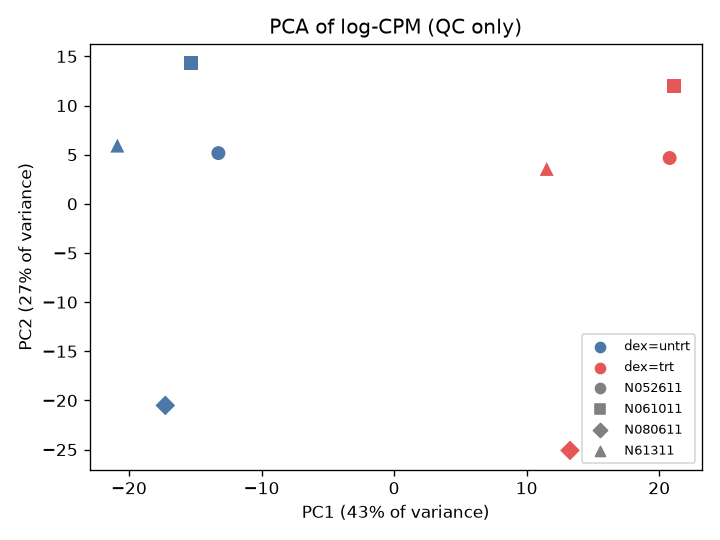

In [5]:
display(Image(q["artifacts"]["pca"], width=520))

PC1 is treatment (dex explains ~95% of its variance), PC2 is donor (cell line explains ~99%). Treatment is the dominant signal, and the donor effect is large: that is what the `cell` term in the design is for.

**The gate on a broken sample.** Scrambling one sample's counts across genes (simulating a mislabeled or degraded library) trips both the PCA and correlation rules:

In [6]:
bad = data.corrupt_counts(ds.counts, "scrambled_sample", "GSM1275867")
qb = qc.run_qc(bad, ds.metadata, out_dir=OUT / "qc_corrupted")
print(qb["passed"]); [f["message"] for f in qb["flags"]]

False


['GSM1275867 is 152.5 PCA units from its group centroid; cutoff is 136.8 (median 27.8 + 3 robust SD).',
 "GSM1275867's best match (GSM1275870) correlates at r=-0.028, below 0.90; its expression profile resembles no other sample."]

## 3. Differential expression

PyDESeq2 with design `~ cell + dex`, Wald test for dex (treated vs untreated), Benjamini–Hochberg adjusted p-values, and LFC shrinkage. "Significant" means padj < 0.05 and |shrunken log2FC| > 1. The reference level is set explicitly to `untrt`: with string labels PyDESeq2 would pick `trt` alphabetically and the shrunken fold changes would flip sign.

In [7]:
d = de.run_de(ds.counts, ds.metadata, ds.gene_map, out_dir=OUT / "de")
print(d["summary"]); print(d["warnings"])
table = pd.read_csv(d["artifacts"]["table"])
table[table.significant].head(20)[["symbol", "baseMean", "log2FC", "log2FC_mle", "stat", "padj", "direction"]]

DE (dex vs untreated, design ~cell + dex): 16,802 genes modelled after low-count filter, 16,802 with an adjusted p-value. 458 up and 421 down at padj<0.05 and |log2FC|>1.
['UserWarning: As the residual degrees of freedom is less than 3, the distribution of log dispersions is especially asymmetric and likely to be poorly estimated by the MAD.']


,symbol,baseMean,log2FC,log2FC_mle,stat,padj,direction
0,SPARCL1,1317.971047,4.604948,4.616470,27.914748,2.968801e-167,up
1,SAMHD1,17750.732909,3.763533,3.772740,26.827555,1.295303e-154,up
2,MAOA,3062.651258,3.332046,3.341409,26.315428,7.153147e-149,up
3,GPX3,16078.471677,3.723925,3.735050,25.784176,5.605335e-143,up
4,DUSP1,4469.035326,2.945861,2.954585,25.481890,1.051784e-139,up
5,SERPINA3,3464.771640,3.216541,3.226287,24.969410,3.680785e-134,up
6,CACNB2,748.926871,3.145133,3.154885,24.792369,2.600876e-132,up
7,VCAM1,658.292691,-3.646868,-3.660365,-23.062446,2.317372e-114,down
8,KLF15,739.962953,4.394559,4.410985,22.986625,1.184242e-113,up
9,TLDC2,884.669818,3.669150,3.683188,22.391865,7.937288e-108,up


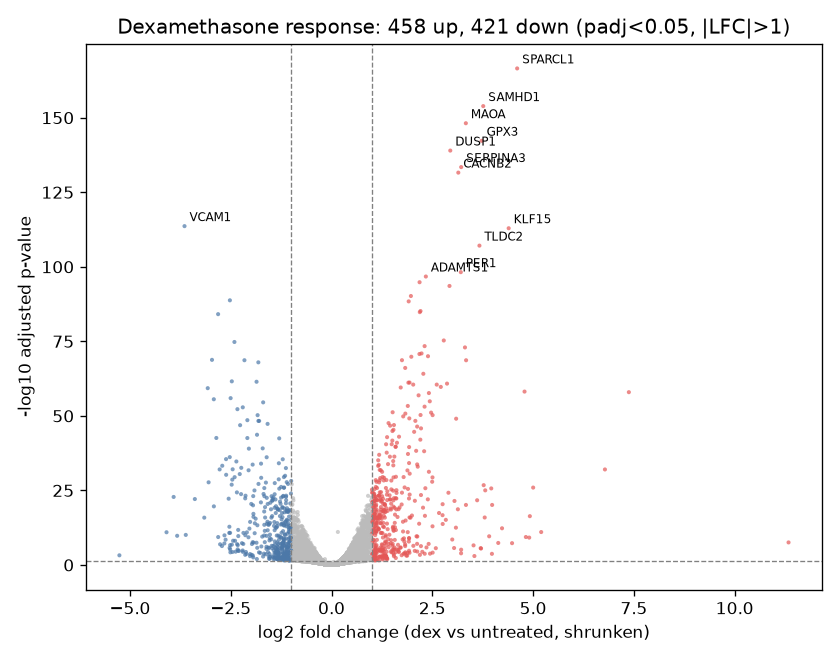

In [8]:
display(Image(d["artifacts"]["volcano"], width=560))

The small-sample warning is expected: 8 samples minus 5 model coefficients leaves 3 residual degrees of freedom. Shrinkage barely moves the estimates here (compare `log2FC` with `log2FC_mle`), a sign the counts are deep and consistent.

## 4. Why the paired design matters

Same data, design `~ dex` (ignoring which donor each sample came from). Donor differences then count as noise, inflating the variance of every gene.

In [9]:
unpaired = {**config.DE_PARAMS, "design": "~dex"}
d0 = de.run_de(ds.counts, ds.metadata, ds.gene_map, out_dir=OUT / "de_unpaired", params=unpaired)
t0 = pd.read_csv(d0["artifacts"]["table"]).drop_duplicates("gene_id").set_index("gene_id")
t1 = table.drop_duplicates("gene_id").set_index("gene_id")
pd.DataFrame({
    "~cell + dex (paired)": [d["n_sig_up"], d["n_sig_down"], round(t1.stat.abs().median(), 2)],
    "~dex (unpaired)": [d0["n_sig_up"], d0["n_sig_down"], round(t0.stat.abs().median(), 2)],
}, index=["significant up", "significant down", "median |Wald stat|"])

,~cell + dex (paired),~dex (unpaired)
significant up,458.00,379.00
significant down,421.00,310.00
median |Wald stat|,1.31,1.14


## 5. Pathway enrichment

Prerank GSEA (gseapy) of all tested genes ranked by Wald statistic against MSigDB Hallmark v2026.2 (50 sets, local file). Unlike over-representation analysis, it needs no significance cutoff and can detect many genes shifting modestly together. Duplicate symbols (from retired NCBI GeneIDs) are collapsed to one row per symbol, preferring the current GeneID.

In [10]:
g = enrichment.run_enrichment(table, out_dir=OUT / "gsea")
print(g["summary"])
gt = pd.read_csv(g["artifacts"]["table"])
gt.head(15)[["term", "nes", "fdr", "set_size", "leading_edge"]].assign(
    leading_edge=lambda x: x.leading_edge.str.split(";").str[:6].str.join(", "))

Prerank GSEA on 16,745 genes ranked by Wald stat against 50 h.all.v2026.2.Hs.symbols.gmt sets (50 within size limits 15-500): 13 enriched among dex-induced genes and 0 among dex-repressed genes at FDR<0.05.


,term,nes,fdr,set_size,leading_edge
0,HALLMARK_ADIPOGENESIS,1.978457,0.001088,200,"SPARCL1, GPX3, STOM, OMD, COL4A1, LEP"
1,HALLMARK_TNFA_SIGNALING_VIA_NFKB,1.829875,0.003264,200,"DUSP1, PER1, PTX3, DNAJB4, IRS2, KLF9"
2,HALLMARK_ANDROGEN_RESPONSE,1.687150,0.014869,101,"ADAMTS1, PDLIM5, TSC22D1, STEAP4, FKBP5, SAT1"
3,HALLMARK_REACTIVE_OXYGEN_SPECIES_PATHWAY,1.650193,0.017189,49,"GPX3, TXNRD1, GCLM, GLRX, SELENOS, GSR"
4,HALLMARK_UV_RESPONSE_DN,1.632805,0.018132,144,"DUSP1, MT1E, COL11A1, PDLIM5, TGFBR2, CITED2"
5,HALLMARK_FATTY_ACID_METABOLISM,1.653993,0.020127,158,"MAOA, ACSS1, ACSL1, PTPRG, ACADS, GLUL"
6,HALLMARK_OXIDATIVE_PHOSPHORYLATION,1.599535,0.022225,200,"ALDH6A1, CPT1A, LDHA, COX11, CYB5A, VDAC2"
7,HALLMARK_XENOBIOTIC_METABOLISM,1.585084,0.022983,200,"MAOA, MT2A, PDLIM5, DCXR, AOX1, ATP2A2"
8,HALLMARK_IL2_STAT5_SIGNALING,1.571471,0.023693,199,"ANXA4, DHRS3, MAFF, NCOA3, GADD45B, KLF6"
9,HALLMARK_UV_RESPONSE_UP,1.514444,0.038296,158,"MAOA, GPX3, HSPA2, IGFBP2, ATF3, TST"


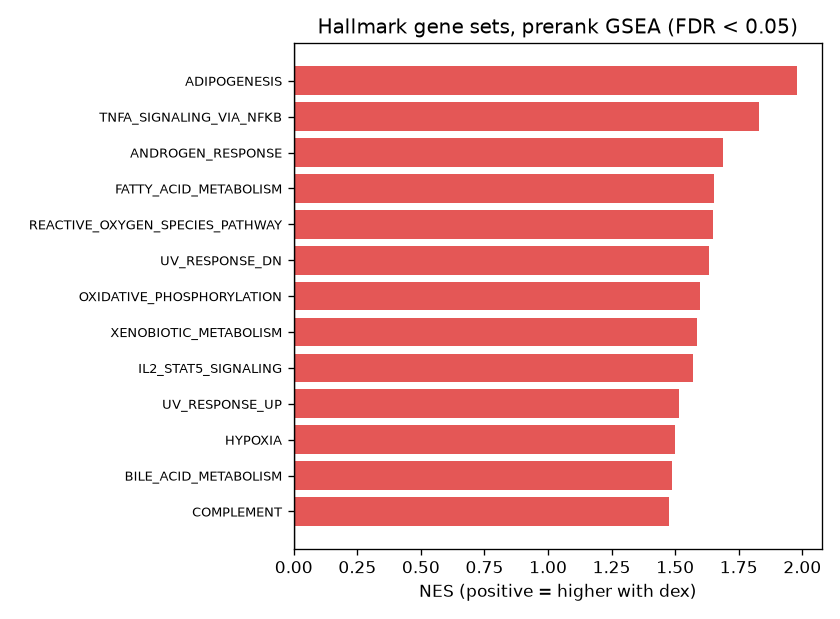

In [11]:
display(Image(g["artifacts"]["plot"], width=560))

**Read the leading edge, not just the name.** `TNFA_SIGNALING_VIA_NFKB` is enriched among *dex-induced* genes, which sounds backwards for an anti-inflammatory drug. Its leading edge is DUSP1, PER1, KLF9 and similar genes. DUSP1 and PER1 are named as well-known glucocorticoid-responsive genes in this dataset's paper (Himes et al. 2014), and KLF9 is glucocorticoid-induced with GR binding sites upstream (Mostafa et al. 2021, *J Biol Chem*). *(Interpretation, not computed here: glucocorticoid targets that sit in the set drive its score.)* This is why the agent cites leading-edge genes.

## 6. Checks

### 6a. Literature genes (sanity check, not ground truth)
Glucocorticoid-responsive genes with literature support: FKBP5, TSC22D3, PER1, KLF15, DUSP1, CRISPLD2 from this dataset's paper (Himes et al. 2014, PMID 24926665); ZBTB16 from an independent airway smooth muscle study (Kan et al. 2019, PMID 30694689). Sources per gene are in `eval/expected.yaml`.

In [12]:
import yaml
exp = yaml.safe_load(open(ROOT / "eval/expected.yaml"))["genes"]
t = table[table.symbol_source == "gene_info"].set_index("symbol")
t.loc[list(exp), ["log2FC", "padj", "direction"]].assign(expected=list(exp.values()))

,log2FC,padj,direction,expected
symbol,,,,
FKBP5,3.962217,2.132311e-26,up,up
TSC22D3,3.134339,2.107786e-19,up,up
PER1,3.207189,6.316373e-99,up,up
KLF15,4.394559,1.184242e-113,up,up
DUSP1,2.945861,1.051784e-139,up,up
ZBTB16,7.375706,1.119732e-58,up,up
CRISPLD2,2.610034,3.239556e-61,up,up


### 6b. Agreement with the study authors' own results
The authors deposited a Cuffdiff dex-vs-untreated table. It is an independent pipeline (different aligner, annotation, model, and unpaired), so the overlap shouldn't be expected to be perfect. Cuffdiff's `log2(fold_change)` is log2(sample_2/sample_1) with sample_1 = Dex, so we flip its sign.

In [13]:
a = pd.read_csv(config.AUTHORS_DE_FILE, sep="\t")
a = a[a.status == "OK"].drop_duplicates("gene").set_index("gene")
a_lfc = -pd.to_numeric(a["log2(fold_change)"], errors="coerce").replace([np.inf, -np.inf], np.nan)
ours = table.drop_duplicates("symbol").set_index("symbol")
common = ours.index.intersection(a.index)
both = [x for x in common if ours.loc[x, "significant"] and a.loc[x, "significant"] == "yes"]
print("genes in common:", len(common))
print("significant here:", int(ours.significant.sum()), "| significant in Cuffdiff:", int((a.significant == "yes").sum()))
print("significant in both:", len(both), "| same direction:", sum((ours.loc[x, "log2FC"] > 0) == (a_lfc[x] > 0) for x in both))
pair = pd.concat([ours.loc[common, "log2FC_mle"], a_lfc[common]], axis=1).dropna()
print("Spearman r of log2FC:", round(pair.corr(method="spearman").iloc[0, 1], 3))

genes in common: 11379
significant here: 876 | significant in Cuffdiff: 316
significant in both: 280 | same direction: 280
Spearman r of log2FC: 0.959


## 7. Edge cases the agent must handle

* **NR3C1** (the glucocorticoid receptor): highly significant padj but |log2FC| just under 1, so *not* counted as significant. The lookup says so explicitly.
* **XIST**: thousands of reads in one donor, near zero in the others, so it fails the low-count filter (needs ≥10 reads in ≥4 samples) and is reported as *not tested*. A female-specific gene would show this pattern. *(Context, not computed.)*

In [14]:
print(t.loc["NR3C1", ["log2FC", "padj", "significant"]].to_dict())
ids = ds.gene_map.loc[ds.gene_map.symbol == "XIST", "gene_id"]
xist = ids[ids.isin(ds.counts.index)].iloc[0]  # XIST has >1 NCBI GeneID; take the counted one
pd.concat([ds.counts.loc[xist].rename("XIST reads"), ds.metadata.cell], axis=1)

{'log2FC': -0.969784625319837, 'padj': 5.033586226371493e-21, 'significant': False}


,XIST reads,cell
GSM1275862,0,N61311
GSM1275863,2,N61311
GSM1275866,4,N052611
GSM1275867,3,N052611
GSM1275870,0,N080611
GSM1275871,0,N080611
GSM1275874,10047,N061011
GSM1275875,8244,N061011


## Reproducibility

Each of these steps, when run through `provenance.execute()` (as the agent and `cli.py` do), writes a run record with input checksums, parameters, software versions and output checksums. `python cli.py reproduce <run_id>` re-runs a record from scratch and verifies the outputs match; in testing, DE and GSEA outputs reproduced byte-for-byte.